<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/11_Vulnerability_Software_Supply_Chain_Attacks/QKMeans_CISAVulnerabilities_ElMaouaki2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum K-means for clustering exploited vulnerabilities: El Maouaki et al. (2024) step by step

This notebook re-implements, runs and checks the method of

> Walid El Maouaki, Nouhaila Innan, Alberto Marchisio, Taoufik Said, Mohamed Bennai and Muhammad Shafique,
> "Quantum Clustering for Cybersecurity", arXiv:2408.02314 [quant-ph], 5 August 2024. https://arxiv.org/abs/2408.02314

The paper publishes no code, so everything below is written from the method as the five-page paper describes it, with the
same software stack it names (PennyLane for the quantum circuits, scikit-learn for the classical pipeline).

**What the notebook does.** It rebuilds the paper's dataset, a 777-row snapshot of the CISA *Known Exploited Vulnerabilities*
(KEV) catalog, from CISA's public feed, label-encodes the two columns the paper clusters (`vendorProject`, `product`), scales
them to $[0, 1]$ for the classical algorithms and to $[0, \pi]$ for the quantum ones, finds $k = 4$ with the elbow method
(paper Fig. 2), and clusters the data with the paper's four algorithms: classical K-means, spectral clustering, and the two
proposed quantum K-means variants, **QCSWAPK-means** (a 5-qubit controlled-SWAP test gives the distance) and
**QkernelK-means** (a 2-qubit quantum kernel $|\langle 0|U^\dagger(c)U(x)|0\rangle|^2$ gives the distance). It then reports
the Silhouette, Davies-Bouldin and Calinski-Harabasz scores of Table I, redraws the cluster scatter plots of Fig. 3, lists which
vendors dominate each cluster, repeats everything over several seeds, and ends with a verdict per claim and a critical
reading of the paper.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs
a pinned PennyLane; if Colab asks to restart the session, restart and run all again. Nothing in the notebook needs a GPU or a
quantum-cloud account.

**Runtime.** The quantum circuits are tiny (2 and 5 qubits, 777 data points), so even the full run is short:
`FAST_MODE = True` (3 restarts, 3 seeds, 256 shots) finishes in about 1 minute, `FAST_MODE = False` (10 restarts per
algorithm, 10 seeds for the stability study, a 1024-shot run of both quantum circuits, 300-start optimum enumeration) in
about 5 minutes on a laptop CPU (the committed outputs are from a full run).

**What you get at the end.** A table with the paper's Table I next to the notebook's numbers and a verdict per claim, a
2 x 2 figure like the paper's Fig. 3, the elbow curve of Fig. 2, a per-cluster vendor breakdown, and an explanation of why
the quantum "distance" used here is, for this data, almost exactly the Euclidean one.

## The paper in one page

**Problem.** Group the vulnerabilities of the CISA Known Exploited Vulnerabilities catalog into clusters of vendors and
products with similar vulnerability profiles, so that defenders can prioritise.

**Decision.** Unsupervised: every CVE is assigned to one of $k$ clusters; there is no ground-truth label, so quality is
measured with internal indices only (Silhouette up, Davies-Bouldin down, Calinski-Harabasz up).

**Method.** Label-encode the two categorical columns *vendor/project* and *product* (paper Fig. 1 also lists
`SimpleImputer`, `StandardScaler`, `MinMaxScaler`), pick $k$ with the elbow method on K-means (Fig. 2, $k = 4$), then run
four algorithms: (a) classical K-means (Euclidean distance), (b) spectral clustering (Gaussian similarity graph, Laplacian
eigenvectors, K-means on them), (c) **QCSWAPK-means**: angle-encode the data point on 2 qubits and the centroid on 2 other
qubits, apply a Hadamard on an ancilla, two controlled-SWAPs, another Hadamard, and read $P(0) = (1 + |\langle\psi(x)|\psi(c)\rangle|^2)/2$
from the ancilla; the point goes to the centroid with the largest overlap, centroids are recomputed as the mean of their
points, repeat until nothing changes; (d) **QkernelK-means**: encode $x$ with $U(x)$ on 2 qubits, apply $U^\dagger(c)$, and
use the probability of $|0\rangle$ as the kernel $K(x, c) = |\langle 0|U^\dagger(c)U(x)|0\rangle|^2$; same assignment and
update rule. The quantum parts are simulated with PennyLane.

**Data.** Kaggle dataset "Cybersecurity Risk (2022 CISA Vulnerability)" (thedevastator), 777 rows, built from the CISA KEV
catalog; columns CVE id, vendor/project, product, vulnerability name, date added, description, required action, due date,
CVSS score, CWE, attack vector, complexity and severity. Only `vendor_project` and `product` are clustered.

**Preprocessing.** Label encoding of the two columns; the classical algorithms see the data normalised to $[0, 1]$, the quantum
ones to $[0, \pi]$ (one qubit per feature, angle encoding).

**Claims (Table I; text of Sections III.A and III.B).**

| Algorithm | Silhouette (higher is better) | Davies-Bouldin (lower) | Calinski-Harabasz (higher) |
|---|---|---|---|
| K-means | 0.451 | 0.883 | 678.137 |
| Spectral clustering | 0.486 | 0.785 | 799.770 |
| QCSWAPK-means | 0.491 | 0.739 | 884.594 |
| QkernelK-means | 0.491 | 0.745 | 885.954 |

Further claims: the elbow is at $k = 4$ (Fig. 2); the final dataset has 777 samples; the quantum methods produce "more
refined and compact clusters" than both classical methods; the quantum clusters are: Cluster 0 mostly critical Microsoft
vulnerabilities, Cluster 1 medium-severity enterprise software and network vendors, Cluster 2 Adobe, Cisco and Google,
Cluster 3 Microsoft and Oracle; K-means Cluster 3 is "heavily dominated by Microsoft".

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | Kaggle "2022 CISA Vulnerability" (777 rows), a snapshot of the CISA KEV catalog | The Kaggle file needs a login; the same rows are rebuilt from CISA's public KEV feed by keeping every entry with `dateAdded <= 2022-06-14`, which gives exactly 777 rows (`# CHOICE`, Section 1) |
| Columns clustered | vendor/project and product | `vendorProject` and `product` of the KEV feed (same fields) |
| Label encoding | "a unique integer to each category" | scikit-learn `LabelEncoder` (alphabetical order); the Kaggle file's spelling of vendor names may differ slightly from today's feed (`# CHOICE`) |
| Imputer / standard scaler | listed in Fig. 1 | applied as listed; both are no-ops for this data (no missing values; min-max after standardisation gives the same numbers) |
| Scaling | $[0, 1]$ classical, $[0, \pi]$ quantum | same; all three indices are invariant to this uniform rescaling, so every algorithm is scored on the $[0, 1]$ data |
| $k$ | 4 (elbow on K-means) | 4; the elbow curve is redrawn and the knee located with the maximum-distance-to-chord rule (`# CHOICE`) |
| Angle encoding | $\cos(x)\lvert 0\rangle + \sin(x)\lvert 1\rangle$ in the text, "one qubit per feature" | `qml.AngleEmbedding(rotation="Y")`, i.e. $R_Y(x)$: $\cos(x/2)\lvert 0\rangle + \sin(x/2)\lvert 1\rangle$, which is injective on $[0, \pi]$; the literal $R_Y(2x)$ version is tested in Section 10 (`# CHOICE`) |
| Kernel read-out | "we measure the first qubit" | probability of the all-zero string $\lvert 00\rangle$, which is the kernel the paper's formula defines; measuring the first qubit alone would ignore the product feature (shown in Section 10) (`# CHOICE`) |
| Centroid initialisation | "k centroids are selected randomly from the dataset" | the same, with `N_INIT` random restarts per algorithm and the run with the lowest within-cluster objective kept (`# CHOICE`) |
| Convergence | "until they meet a predefined convergence criterion" | stop when no assignment changes or after `MAX_ITER` iterations (`# CHOICE`) |
| Shots / noise | not stated | exact probabilities (statevector) for the main results; a 1024-shot run in Section 7 (`# CHOICE`) |
| Spectral clustering | Gaussian similarity, Laplacian eigenvectors, K-means | `SpectralClustering(affinity="rbf", gamma=1.0, assign_labels="kmeans")` (`# CHOICE`, scikit-learn defaults) |
| Seeds, restarts | not stated | `SEED = 42`; K-means `n_init = 10`; quantum algorithms `N_INIT` restarts; stability over `N_SEEDS` seeds |
| Severity / CVSS per cluster | described in the text | the public KEV feed has no CVSS column, so severity statements cannot be checked; vendor composition can |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False        # True: class demo (about 2 min). False: full budgets described below (about 5 min on a laptop CPU).

SEED      = 42            # CHOICE: the paper gives no seed
K         = 4             # paper: elbow method -> 4 clusters
N_QUBITS  = 2             # one qubit per feature (vendor, product); the CSWAP circuit uses 2 + 2 + 1 ancilla = 5 qubits
SNAPSHOT_DATE = "2022-06-14"   # CHOICE: the KEV catalog up to this day has exactly the paper's 777 rows (Section 1)

if FAST_MODE:
    N_INIT   = 3          # random restarts of each quantum K-means
    MAX_ITER = 30         # iteration cap of one quantum K-means run
    N_SEEDS  = 3          # seeds for the stability study (Section 9)
    SHOTS    = 256        # shots for the finite-shot run (Section 7)
else:
    N_INIT   = 10         # CHOICE: the paper reports a single run without restarts
    MAX_ITER = 100
    N_SEEDS  = 10
    SHOTS    = 1024       # CHOICE: the paper does not state a shot count

ANGLE_FACTOR  = 1.0       # CHOICE: R_Y(ANGLE_FACTOR * x); 1.0 = PennyLane AngleEmbedding, 2.0 = the paper's literal cos(x)|0> + sin(x)|1>
SPECTRAL_GAMMA = 1.0      # CHOICE: width of the Gaussian similarity in spectral clustering (scikit-learn default)
N_INIT_KMEANS = 10        # CHOICE: scikit-learn K-means restarts

DATA_DIR  = "data"        # where the catalog CSV is cached (relative to the working directory)
KEV_CSV   = "https://www.cisa.gov/sites/default/files/csv/known_exploited_vulnerabilities.csv"
KEV_JSON  = "https://www.cisa.gov/sites/default/files/feeds/known_exploited_vulnerabilities.json"   # fallback
UPLOADED_CSV = ""         # optional: path to a locally saved KEV csv (or the Kaggle csv) to use instead of downloading

In [3]:
import os, io, time, json, warnings, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

import pennylane as qml
warnings.filterwarnings("ignore", category=qml.exceptions.PennyLaneDeprecationWarning)

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)

print("pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print(f"FAST_MODE = {FAST_MODE} | K = {K} | N_INIT = {N_INIT} | MAX_ITER = {MAX_ITER} | N_SEEDS = {N_SEEDS} | SHOTS = {SHOTS}")

pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | K = 4 | N_INIT = 10 | MAX_ITER = 100 | N_SEEDS = 10 | SHOTS = 1024


## 1. The data: a 777-row snapshot of the CISA Known Exploited Vulnerabilities catalog

The paper takes its data from a Kaggle upload, "Cybersecurity Risk (2022 CISA Vulnerability)", and says the final dataset has
**777 samples**. Kaggle files need a login, so the notebook goes to the original source instead: CISA publishes the KEV catalog
as a CSV and a JSON feed at `cisa.gov`, one row per exploited CVE with the vendor/project, product, vulnerability name, date
added, description, required action and due date. The catalog only grows (entries are added almost every week, very rarely
withdrawn), so a snapshot of mid-2022 is recovered by keeping the entries whose `dateAdded` is on or before a cut-off date.
Sorting the live catalog by `dateAdded`, the 777th entry is CVE-2022-30190 ("Follina"), added on **14 June 2022**; the cut-off
`SNAPSHOT_DATE = "2022-06-14"` therefore reproduces the paper's row count exactly, and the cell checks it. (The Kaggle upload
also carried CVSS, CWE, attack-vector and severity columns pulled from the NVD; those are not in the CISA feed and are not used
by the paper's clustering, only in its prose, see Section 8.)

If the download fails, the JSON feed is tried; `UPLOADED_CSV` lets you point at a saved copy (the Kaggle CSV works too: its
columns `vendor_project` / `product` / `date_added` are renamed below).

using cached data\cisa_kev_catalog.csv
loaded in 0.1 s: 1,748 catalog entries, 2021-11-03 .. 2026-10-16
snapshot up to 2022-06-14: 777 rows   (paper: 777 samples)
distinct vendors/projects: 130 | distinct products: 327
missing values in the two clustered columns: 0


,cveID,vendorProject,product,vulnerabilityName,dateAdded
0,CVE-2010-5326,SAP,NetWeaver,SAP NetWeaver Remote Code Execution Vulnerability,2021-11-03
1,CVE-2012-0158,Microsoft,MSCOMCTL.OCX,Microsoft MSCOMCTL.OCX Remote Code Execution Vulnerability,2021-11-03
2,CVE-2012-3152,Oracle,Fusion Middleware,Oracle Fusion Middleware Unspecified Vulnerability,2021-11-03
3,CVE-2014-1812,Microsoft,Windows,Microsoft Windows Group Policy Preferences Password Privilege Escalation Vul...,2021-11-03
4,CVE-2015-1641,Microsoft,Office,Microsoft Office Memory Corruption Vulnerability,2021-11-03


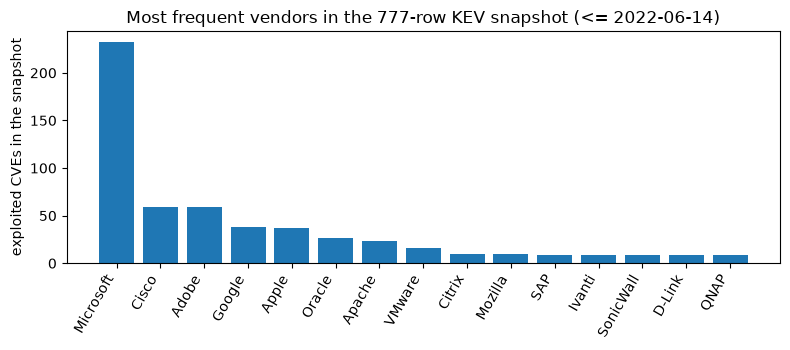

In [4]:
CSV_PATH = os.path.join(DATA_DIR, "cisa_kev_catalog.csv")

def fetch_kev(path):
    """Download the CISA KEV catalog (CSV, falling back to the JSON feed) and cache it as CSV."""
    if UPLOADED_CSV and os.path.exists(UPLOADED_CSV):
        print("using uploaded file", UPLOADED_CSV); return pd.read_csv(UPLOADED_CSV)
    if os.path.exists(path):
        print("using cached", path); return pd.read_csv(path)
    import requests
    try:
        r = requests.get(KEV_CSV, timeout=120); r.raise_for_status()
        df = pd.read_csv(io.BytesIO(r.content)); print("downloaded CSV feed from cisa.gov")
    except Exception as e:
        print(f"CSV feed failed ({type(e).__name__}); trying the JSON feed")
        r = requests.get(KEV_JSON, timeout=120); r.raise_for_status()
        df = pd.DataFrame(r.json()["vulnerabilities"]); print("downloaded JSON feed from cisa.gov")
    df.to_csv(path, index=False)
    return df

t0 = time.time()
raw = fetch_kev(CSV_PATH)
raw = raw.rename(columns={"vendor_project": "vendorProject", "date_added": "dateAdded", "cve_id": "cveID"})  # Kaggle spelling
raw["dateAdded"] = pd.to_datetime(raw["dateAdded"])
print(f"loaded in {time.time()-t0:.1f} s: {len(raw):,} catalog entries, {raw['dateAdded'].min().date()} .. {raw['dateAdded'].max().date()}")

df = raw[raw["dateAdded"] <= pd.Timestamp(SNAPSHOT_DATE)].sort_values(["dateAdded", "cveID"]).reset_index(drop=True)
print(f"snapshot up to {SNAPSHOT_DATE}: {len(df)} rows   (paper: 777 samples)")
if len(df) != 777:
    print("NOTE: the live catalog no longer has exactly 777 entries up to the cut-off (entries withdrawn or re-dated); "
          "the notebook continues with the rows it has.")
print(f"distinct vendors/projects: {df['vendorProject'].nunique()} | distinct products: {df['product'].nunique()}")
print("missing values in the two clustered columns:", int(df[['vendorProject', 'product']].isnull().sum().sum()))
display(df[["cveID", "vendorProject", "product", "vulnerabilityName", "dateAdded"]].head(5))

top = df["vendorProject"].value_counts().head(15)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(top.index, top.values, color="tab:blue"); ax.set_ylabel("exploited CVEs in the snapshot")
ax.set_title(f"Most frequent vendors in the {len(df)}-row KEV snapshot (<= {SNAPSHOT_DATE})")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()

## 2. Preprocessing: label encoding and two scalings

The paper clusters only the two categorical columns and turns them into numbers with *label encoding*: each distinct vendor
gets an integer, each distinct product gets an integer. `LabelEncoder` numbers the categories in alphabetical order, so
"Adobe" is a small number and "Zoho" a large one; the Kaggle file may spell some vendors differently from today's feed
(`# CHOICE`), which would shift a few integers but not the structure of the data. The pipeline in the paper's Fig. 1 then
applies `SimpleImputer`, `StandardScaler` and `MinMaxScaler`; the imputer finds nothing to impute and a standardisation
followed by min-max scaling gives exactly the min-max result, so the two scalers are kept for fidelity but change nothing.
Classical algorithms see the data in $[0, 1]$, the quantum circuits in $[0, \pi]$ (one rotation angle per qubit). Because
the two scalings differ by the constant factor $\pi$, every clustering index below is invariant to the choice, and the
notebook scores all four algorithms on the $[0, 1]$ version (checked numerically in Section 8).

The scatter plot already tells most of the story: the data are integers on a 130 x 327 grid, with vertical streaks for vendors
that have many products (Microsoft, Apple, Cisco) and a dense diagonal band of vendors with one or two products each.

label-encoded features: (777, 2) | vendor codes 0..129 | product codes 0..326
example: SAP -> 91 | NetWeaver -> 189


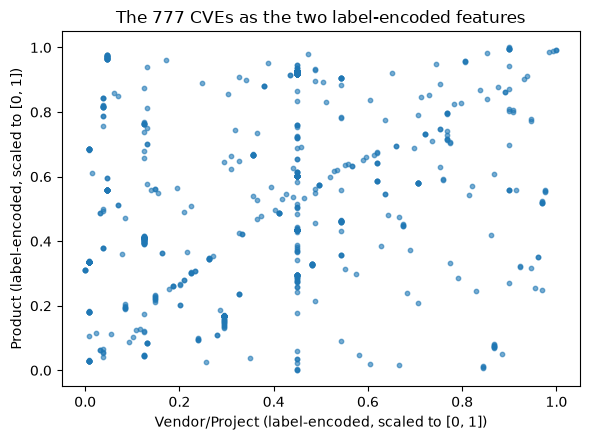

In [5]:
enc_vendor, enc_product = LabelEncoder(), LabelEncoder()
X_int = np.c_[enc_vendor.fit_transform(df["vendorProject"]), enc_product.fit_transform(df["product"])].astype(float)
X_imp = SimpleImputer(strategy="mean").fit_transform(X_int)            # paper Fig. 1: SimpleImputer (no-op here)
X_std = StandardScaler().fit_transform(X_imp)                          # paper Fig. 1: StandardScaler
X01   = MinMaxScaler((0, 1)).fit_transform(X_std)                      # classical algorithms: [0, 1]
Xpi   = MinMaxScaler((0, np.pi)).fit_transform(X_std)                  # quantum algorithms: [0, pi] (angle encoding)
assert np.allclose(Xpi, np.pi * X01)
FEATURES = ["Vendor/Project", "Product"]
print("label-encoded features:", X_int.shape, "| vendor codes 0..%d | product codes 0..%d" % (X_int[:, 0].max(), X_int[:, 1].max()))
print("example:", df.loc[0, "vendorProject"], "->", int(X_int[0, 0]), "|", df.loc[0, "product"], "->", int(X_int[0, 1]))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(X01[:, 0], X01[:, 1], s=10, alpha=0.6)
ax.set_xlabel(FEATURES[0] + " (label-encoded, scaled to [0, 1])"); ax.set_ylabel(FEATURES[1] + " (label-encoded, scaled to [0, 1])")
ax.set_title("The 777 CVEs as the two label-encoded features"); plt.tight_layout(); plt.show()

## 3. How many clusters? The elbow method (paper Fig. 2)

The paper runs K-means for a range of $k$, plots the within-cluster sum of squares (WCSS, Eq. 2) and reads the elbow at
$k = 4$. Reading an elbow by eye is subjective, so besides drawing the curve the cell also computes a common objective
version of the rule: the point of the curve farthest from the straight line joining its two ends (`# CHOICE`). The
notebook keeps the paper's $k = 4$ whatever the rule says, and reports what it says.

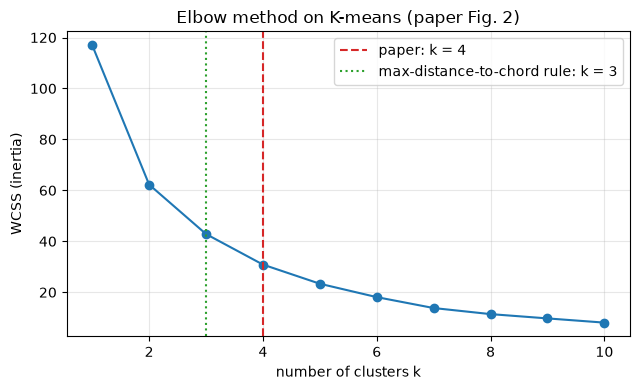

k =  1: WCSS =  116.979
k =  2: WCSS =   62.262 | K-means silhouette 0.430
k =  3: WCSS =   42.844 | K-means silhouette 0.428
k =  4: WCSS =   30.858 | K-means silhouette 0.453   <- paper's choice
k =  5: WCSS =   23.341 | K-means silhouette 0.490
k =  6: WCSS =   18.085 | K-means silhouette 0.526
k =  7: WCSS =   13.801 | K-means silhouette 0.534
k =  8: WCSS =   11.417 | K-means silhouette 0.531
k =  9: WCSS =    9.734 | K-means silhouette 0.544
k = 10: WCSS =    8.077 | K-means silhouette 0.552


In [6]:
ks = list(range(1, 11))
wcss = [KMeans(n_clusters=k, n_init=N_INIT_KMEANS, random_state=SEED).fit(X01).inertia_ for k in ks]

# CHOICE: knee = point with the largest distance to the chord between (k=1, wcss[0]) and (k=10, wcss[-1]), after normalising both axes
p = np.c_[(np.array(ks) - ks[0]) / (ks[-1] - ks[0]), (np.array(wcss) - wcss[-1]) / (wcss[0] - wcss[-1])]
chord = p[-1] - p[0]; chord /= np.linalg.norm(chord)
q = p - p[0]; dist = np.abs(q[:, 0] * chord[1] - q[:, 1] * chord[0])   # perpendicular distance of each point to the chord
knee = ks[int(np.argmax(dist))]
sil_by_k = {k: silhouette_score(X01, KMeans(n_clusters=k, n_init=N_INIT_KMEANS, random_state=SEED).fit_predict(X01)) for k in ks[1:]}

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(ks, wcss, "o-", color="tab:blue"); ax.axvline(K, color="tab:red", ls="--", label=f"paper: k = {K}")
ax.axvline(knee, color="tab:green", ls=":", label=f"max-distance-to-chord rule: k = {knee}")
ax.set_xlabel("number of clusters k"); ax.set_ylabel("WCSS (inertia)"); ax.set_title("Elbow method on K-means (paper Fig. 2)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
for k, w in zip(ks, wcss):
    print(f"k = {k:2d}: WCSS = {w:8.3f}" + (f" | K-means silhouette {sil_by_k[k]:.3f}" if k in sil_by_k else "")
          + ("   <- paper's choice" if k == K else ""))

## 4. The three clustering indices and the two classical algorithms

All three scores in Table I are *internal* indices (no labels needed):

* **Silhouette** (Rousseeuw 1987): for each point, $(b - a) / \max(a, b)$ where $a$ is the mean distance to its own cluster
  and $b$ the mean distance to the nearest other cluster; averaged over points; in $[-1, 1]$, higher is better.
* **Davies-Bouldin**: average over clusters of the worst ratio (sum of the two clusters' mean radii) / (distance between
  their centroids); lower is better.
* **Calinski-Harabasz**: between-cluster dispersion over within-cluster dispersion, scaled by $(n - k)/(k - 1)$; higher is
  better. It grows with $n$ and is not comparable across datasets of different size, so the paper's values of 678-886 only
  make sense because every algorithm sees the same 777 points.

The two classical competitors are scikit-learn's `KMeans` (k-means++ initialisation, `N_INIT_KMEANS` restarts) and
`SpectralClustering` with the Gaussian (RBF) affinity the paper describes.

In [7]:
def cluster_scores(X, labels):
    """Silhouette, Davies-Bouldin, Calinski-Harabasz (as in Table I of the paper)."""
    if len(np.unique(labels)) < 2:
        return dict(silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    return dict(silhouette=silhouette_score(X, labels), davies_bouldin=davies_bouldin_score(X, labels),
                calinski_harabasz=calinski_harabasz_score(X, labels))

def centroids_of(X, labels, k=K):
    return np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else np.full(X.shape[1], np.nan) for j in range(k)])

results = {}            # algorithm -> dict(labels, centroids (in [0,1] space), scores, seconds)

t0 = time.perf_counter()
km = KMeans(n_clusters=K, n_init=N_INIT_KMEANS, random_state=SEED).fit(X01)
results["K-means"] = dict(labels=km.labels_, centroids=km.cluster_centers_, seconds=time.perf_counter() - t0,
                          iterations=km.n_iter_, **cluster_scores(X01, km.labels_))

t0 = time.perf_counter()
sp = SpectralClustering(n_clusters=K, affinity="rbf", gamma=SPECTRAL_GAMMA, assign_labels="kmeans",
                        n_init=N_INIT_KMEANS, random_state=SEED).fit(X01)   # CHOICE: rbf affinity, gamma = SPECTRAL_GAMMA
results["Spectral clustering"] = dict(labels=sp.labels_, centroids=centroids_of(X01, sp.labels_),
                                      seconds=time.perf_counter() - t0, iterations=None, **cluster_scores(X01, sp.labels_))

for name, r in results.items():
    print(f"{name:20s} silhouette {r['silhouette']:.3f} | Davies-Bouldin {r['davies_bouldin']:.3f} | "
          f"Calinski-Harabasz {r['calinski_harabasz']:.1f} | {r['seconds']:.2f} s | sizes {np.bincount(r['labels'], minlength=K)}")

K-means              silhouette 0.453 | Davies-Bouldin 0.792 | Calinski-Harabasz 719.1 | 0.02 s | sizes [108 237 219 213]
Spectral clustering  silhouette 0.418 | Davies-Bouldin 0.809 | Calinski-Harabasz 618.7 | 0.24 s | sizes [215 248  56 258]


## 5. Angle encoding and the two quantum distance circuits

**Angle encoding.** Each of the two features becomes a rotation angle of one qubit: $|\psi(x)\rangle = R_Y(x_1)|0\rangle \otimes R_Y(x_2)|0\rangle$
with $R_Y(\theta)|0\rangle = \cos(\theta/2)|0\rangle + \sin(\theta/2)|1\rangle$. This is PennyLane's `AngleEmbedding`; the paper
writes the state as $\cos(x)|0\rangle + \sin(x)|1\rangle$, which is $R_Y(2x)$ and maps $x = 0$ and $x = \pi$ to the same
state (up to sign), so a vendor at the top of the alphabet and one at the bottom would be "identical". `ANGLE_FACTOR`
switches between the two readings; Section 10 shows what the literal version does.

**QCSWAPK-means (5 qubits).** Ancilla in $|+\rangle$, data point on qubits 1-2, centroid on qubits 3-4, a controlled-SWAP
of each data qubit with its centroid qubit, a final Hadamard, and the ancilla is measured:
$P(0) = \tfrac{1}{2}\left(1 + |\langle\psi(x)|\psi(c)\rangle|^2\right)$. The overlap $F = 2P(0) - 1$ is the similarity; the point
joins the centroid with the largest $F$.

**QkernelK-means (2 qubits).** Prepare $U(x)|0\rangle$, apply $U^\dagger(c)$, measure both qubits: the probability of
$|00\rangle$ is $K(x, c) = |\langle 0|U^\dagger(c) U(x)|0\rangle|^2 = |\langle\psi(c)|\psi(x)\rangle|^2$, the fidelity
kernel of a QSVM. The paper says it "measures the first qubit"; the probability of $0$ on the first qubit alone is
$\cos^2((x_1 - c_1)/2)$ and does not depend on the product feature at all, so the notebook reads the full $|00\rangle$
probability, which is the quantity the paper's formula defines (`# CHOICE`; Section 10 runs the one-qubit read-out too).

**What the circuits compute.** For product-state angle encoding both circuits evaluate the same closed-form number,
$$F(x, c) = \prod_{i=1}^{2} \cos^2\!\left(\tfrac{x_i - c_i}{2}\right),$$
and the cell below checks the simulator against this formula to machine precision. For small angle differences
$\cos^2(\delta/2) \approx 1 - \delta^2/4$, so $F \approx 1 - \|x - c\|^2/4$: maximising the overlap is, to first order,
minimising the Euclidean distance that classical K-means uses. This matters for reading the paper's results and is taken
up again at the end.

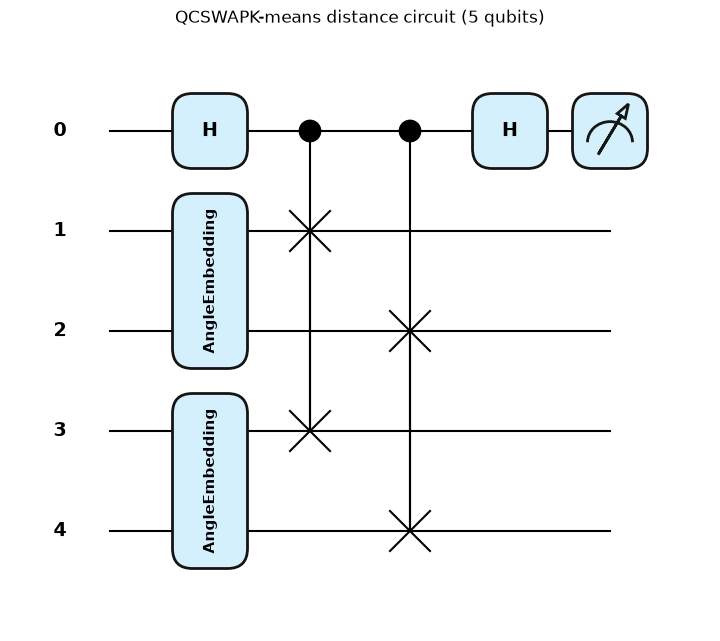

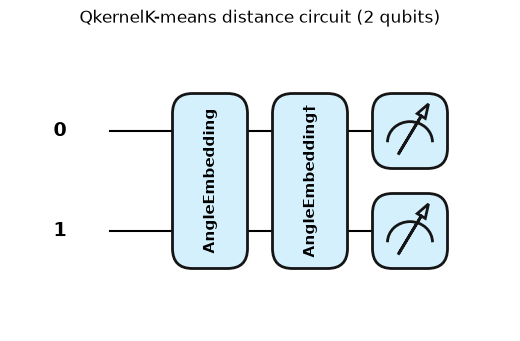

CSWAP overlaps for 777 points x 4 centroids: 0.02 s | max |circuit - closed form| = 1.9e-15
kernel overlaps                           : 0.02 s | max |circuit - closed form| = 5.6e-16
max |CSWAP - kernel| = 1.7e-15  (the two circuits measure the same fidelity)


In [8]:
dev_cswap  = qml.device("default.qubit", wires=5, seed=SEED)
dev_kernel = qml.device("default.qubit", wires=N_QUBITS, seed=SEED)

def encode(x, wires):
    qml.AngleEmbedding(ANGLE_FACTOR * x, wires=wires, rotation="Y")   # R_Y(ANGLE_FACTOR * x_i) on each qubit

@qml.qnode(dev_cswap)
def cswap_test(x, c):
    """Controlled-SWAP test: P(ancilla = 0) = (1 + |<psi(x)|psi(c)>|^2) / 2."""
    qml.Hadamard(wires=0)
    encode(x, wires=[1, 2])
    encode(c, wires=[3, 4])
    qml.CSWAP(wires=[0, 1, 3])
    qml.CSWAP(wires=[0, 2, 4])
    qml.Hadamard(wires=0)
    return qml.probs(wires=0)

@qml.qnode(dev_kernel)
def kernel_circuit(x, c):
    """Quantum kernel: P(|00>) = |<0| U^+(c) U(x) |0>|^2."""
    encode(x, wires=[0, 1])
    qml.adjoint(encode)(c, wires=[0, 1])
    return qml.probs(wires=[0, 1])

def overlap_cswap(X, C, qnode=cswap_test):
    """Overlap matrix F[i, j] = |<psi(x_i)|psi(c_j)>|^2 from the CSWAP test, one broadcast circuit per centroid."""
    F = np.empty((len(X), len(C)))
    for j, c in enumerate(C):
        p0 = np.asarray(qnode(X, np.broadcast_to(c, X.shape)))[:, 0]
        F[:, j] = 2.0 * p0 - 1.0
    return F

def overlap_kernel(X, C, qnode=kernel_circuit, first_qubit_only=False):
    """Overlap matrix from the kernel circuit: probability of |00> (or of 0 on the first qubit, the paper's wording)."""
    F = np.empty((len(X), len(C)))
    for j, c in enumerate(C):
        p = np.asarray(qnode(X, np.broadcast_to(c, X.shape)))
        F[:, j] = p[:, 0] + p[:, 1] if first_qubit_only else p[:, 0]   # basis order |00>,|01>,|10>,|11>
    return F

def overlap_closed_form(X, C):
    """prod_i cos^2(ANGLE_FACTOR * (x_i - c_i) / 2): what both circuits compute for product-state angle encoding."""
    D = ANGLE_FACTOR * (X[:, None, :] - C[None, :, :])
    return np.prod(np.cos(D / 2.0) ** 2, axis=2)

x_demo, c_demo = Xpi[0], Xpi[1]
fig, ax = qml.draw_mpl(cswap_test, decimals=2, style="pennylane")(x_demo, c_demo); ax.set_title("QCSWAPK-means distance circuit (5 qubits)"); plt.show()
fig, ax = qml.draw_mpl(kernel_circuit, decimals=2, style="pennylane")(x_demo, c_demo); ax.set_title("QkernelK-means distance circuit (2 qubits)"); plt.show()

C_demo = Xpi[rng.choice(len(Xpi), K, replace=False)]
t0 = time.perf_counter(); F_cswap = overlap_cswap(Xpi, C_demo); t_cswap = time.perf_counter() - t0
t0 = time.perf_counter(); F_kern = overlap_kernel(Xpi, C_demo); t_kern = time.perf_counter() - t0
F_exact = overlap_closed_form(Xpi, C_demo)
print(f"CSWAP overlaps for {len(Xpi)} points x {K} centroids: {t_cswap:.2f} s | max |circuit - closed form| = {np.abs(F_cswap - F_exact).max():.1e}")
print(f"kernel overlaps                           : {t_kern:.2f} s | max |circuit - closed form| = {np.abs(F_kern - F_exact).max():.1e}")
print(f"max |CSWAP - kernel| = {np.abs(F_cswap - F_kern).max():.1e}  (the two circuits measure the same fidelity)")

## 6. The quantum K-means loop

Both quantum algorithms are the Lloyd iteration of K-means with the Euclidean distance replaced by the circuit overlap:

1. draw $k$ centroids at random from the data (paper);
2. **assignment**: run the circuit for every (point, centroid) pair and send each point to the centroid with the largest
   overlap;
3. **update**: each centroid becomes the mean (in angle space) of its points;
4. stop when no assignment changed (or after `MAX_ITER` iterations).

The paper reports one run per algorithm. K-means-type algorithms land in different local optima from different random
starts, so the notebook performs `N_INIT` restarts and keeps the one with the smallest within-cluster *quantum* objective
$\sum_i (1 - F(x_i, c_{\ell(i)}))$ (`# CHOICE`), which is the overlap analogue of the WCSS. The live plot shows the
objective of every restart iteration by iteration. The cell also records the number of circuit evaluations: every
iteration runs $777 \times 4$ circuits, which on a real device would each need many shots (Section 7).

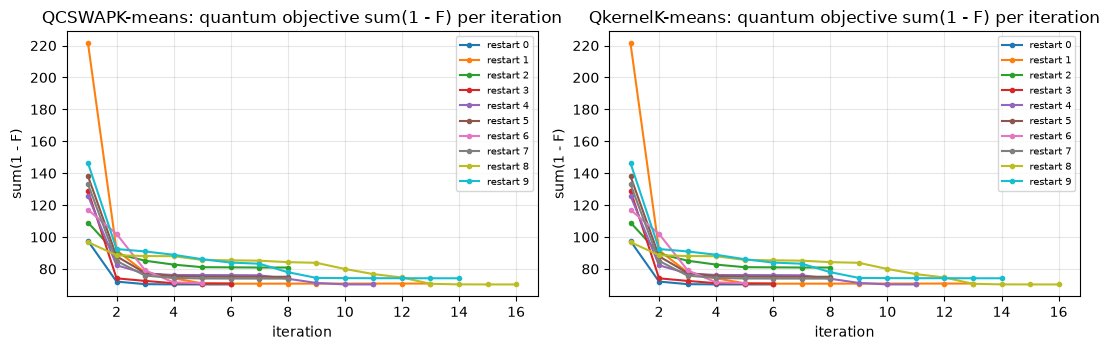

QCSWAPK-means    best restart 0 converged in 6 iterations (18,648 circuit evaluations in the kept run), 5.6 s for 10 restarts | silhouette 0.453 | DB 0.792 | CH 719.1 | sizes [213 108 219 237]
QkernelK-means   best restart 0 converged in 6 iterations (18,648 circuit evaluations in the kept run), 6.1 s for 10 restarts | silhouette 0.453 | DB 0.792 | CH 719.1 | sizes [213 108 219 237]


In [9]:
def quantum_kmeans(X, k, overlap_fn, seed, n_init=N_INIT, max_iter=MAX_ITER, trace=None):
    """K-means with the assignment step done by a quantum overlap circuit. Returns the best of n_init restarts."""
    best = None
    rs = np.random.default_rng(seed)
    for restart in range(n_init):
        C = X[rs.choice(len(X), k, replace=False)].copy()        # paper: k centroids selected randomly from the dataset
        labels, history, n_circuits = None, [], 0
        for it in range(1, max_iter + 1):
            F = overlap_fn(X, C); n_circuits += F.size
            new_labels = F.argmax(axis=1)
            objective = float(np.sum(1.0 - F[np.arange(len(X)), new_labels]))
            history.append(objective)
            if labels is not None and np.array_equal(new_labels, labels):
                break
            labels = new_labels
            for j in range(k):                                     # update: mean of the assigned points (angle space)
                if np.any(labels == j):
                    C[j] = X[labels == j].mean(axis=0)
        run = dict(labels=labels, centroids_angle=C, objective=history[-1], history=history,
                   iterations=it, circuits=n_circuits, restart=restart)
        if trace is not None:
            trace(restart, history)                                # live plot: one curve per finished restart
        if best is None or run["objective"] < best["objective"]:  # CHOICE: keep the restart with the lowest quantum objective
            best = run
    return best

QUANTUM = {"QCSWAPK-means": overlap_cswap, "QkernelK-means": overlap_kernel}
live = {}

def draw_live():
    clear_output(wait=True)
    fig, axes = plt.subplots(1, len(QUANTUM), figsize=(5.5 * len(QUANTUM), 3.6), squeeze=False)
    for ax, (name, runs) in zip(axes[0], live.items()):
        for restart, h in runs.items():
            ax.plot(range(1, len(h) + 1), h, marker=".", label=f"restart {restart}")
        ax.set_title(f"{name}: quantum objective sum(1 - F) per iteration"); ax.set_xlabel("iteration"); ax.set_ylabel("sum(1 - F)")
        ax.grid(alpha=0.3)
        if runs: ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()

for name, fn in QUANTUM.items():
    live[name] = {}
    def trace(restart, history, name=name):
        live[name][restart] = list(history); draw_live()
    t0 = time.perf_counter()
    best = quantum_kmeans(Xpi, K, fn, seed=SEED, trace=trace)
    secs = time.perf_counter() - t0
    results[name] = dict(labels=best["labels"], centroids=best["centroids_angle"] / np.pi,   # back to the [0,1] frame of the plots
                         seconds=secs, iterations=best["iterations"], circuits=best["circuits"], objective=best["objective"],
                         restart=best["restart"], **cluster_scores(X01, best["labels"]))
draw_live()
for name in QUANTUM:
    r = results[name]
    print(f"{name:16s} best restart {r['restart']} converged in {r['iterations']} iterations ({r['circuits']:,} circuit evaluations in the kept run), "
          f"{r['seconds']:.1f} s for {N_INIT} restarts | silhouette {r['silhouette']:.3f} | DB {r['davies_bouldin']:.3f} | "
          f"CH {r['calinski_harabasz']:.1f} | sizes {np.bincount(r['labels'], minlength=K)}")

## 7. The same circuits with a finite number of shots

Exact probabilities are a simulator's luxury: a real device estimates $P(0)$ from `SHOTS` repetitions, with a standard error
of about $\sqrt{P(1-P)/\text{shots}}$ on each overlap (about 0.016 for 1024 shots). This cell repeats one restart of both
algorithms with sampled probabilities (`qml.set_shots`), starting from the same centroids as the best exact run, and reports
how much the indices move. With shot noise the assignment may never become exactly stable, so the loop ends at `MAX_ITER`
or when the labels repeat.

In [10]:
cswap_shots  = qml.set_shots(cswap_test, shots=SHOTS)
kernel_shots = qml.set_shots(kernel_circuit, shots=SHOTS)
QUANTUM_SHOTS = {"QCSWAPK-means": lambda X, C: overlap_cswap(X, C, qnode=cswap_shots),
                 "QkernelK-means": lambda X, C: overlap_kernel(X, C, qnode=kernel_shots)}

shot_rows = []
for name, fn in QUANTUM_SHOTS.items():
    t0 = time.perf_counter()
    run = quantum_kmeans(Xpi, K, fn, seed=SEED + 1, n_init=1, max_iter=MAX_ITER)
    secs = time.perf_counter() - t0
    sc = cluster_scores(X01, run["labels"])
    shot_rows.append(dict(algorithm=f"{name} ({SHOTS} shots)", iterations=run["iterations"], seconds=round(secs, 1),
                          silhouette=round(sc["silhouette"], 3), davies_bouldin=round(sc["davies_bouldin"], 3),
                          calinski_harabasz=round(sc["calinski_harabasz"], 1),
                          ARI_vs_exact=round(adjusted_rand_score(results[name]["labels"], run["labels"]), 3)))
    results[f"{name} ({SHOTS} shots)"] = dict(labels=run["labels"], centroids=run["centroids_angle"] / np.pi, seconds=secs,
                                             iterations=run["iterations"], **sc)
shots_df = pd.DataFrame(shot_rows)
print(f"finite-shot runs ({SHOTS} shots per circuit; ARI = adjusted Rand index of the partition against the exact run):")
display(shots_df)

finite-shot runs (1024 shots per circuit; ARI = adjusted Rand index of the partition against the exact run):


,algorithm,iterations,seconds,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_exact
0,QCSWAPK-means (1024 shots),100,76.7,0.454,0.820,712.8,0.653
1,QkernelK-means (1024 shots),79,74.0,0.454,0.823,714.1,0.641


## 8. Table I and Fig. 3 of the paper

The table collects the three indices for every algorithm (the two finite-shot runs included), and the 2 x 2 figure is the
paper's Fig. 3: vendor/project on the x-axis, product on the y-axis, one colour per cluster, red X markers at the
centroids. Spectral clustering has no centroids of its own, so the cluster means are drawn. The last line of the cell
confirms that scoring the quantum partitions on the $[0, \pi]$ data instead of $[0, 1]$ gives the same three numbers.

This notebook's version of Table I (all algorithms scored on the same [0, 1] data):


,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz,seconds,cluster sizes
0,K-means,0.453,0.792,719.103,0.02,[108 237 219 213]
1,Spectral clustering,0.418,0.809,618.744,0.24,[215 248 56 258]
2,QCSWAPK-means,0.453,0.792,719.103,5.55,[213 108 219 237]
3,QkernelK-means,0.453,0.792,719.103,6.09,[213 108 219 237]
4,QCSWAPK-means (1024 shots),0.454,0.820,712.761,76.69,[245 96 207 229]
5,QkernelK-means (1024 shots),0.454,0.823,714.060,73.98,[242 97 209 229]


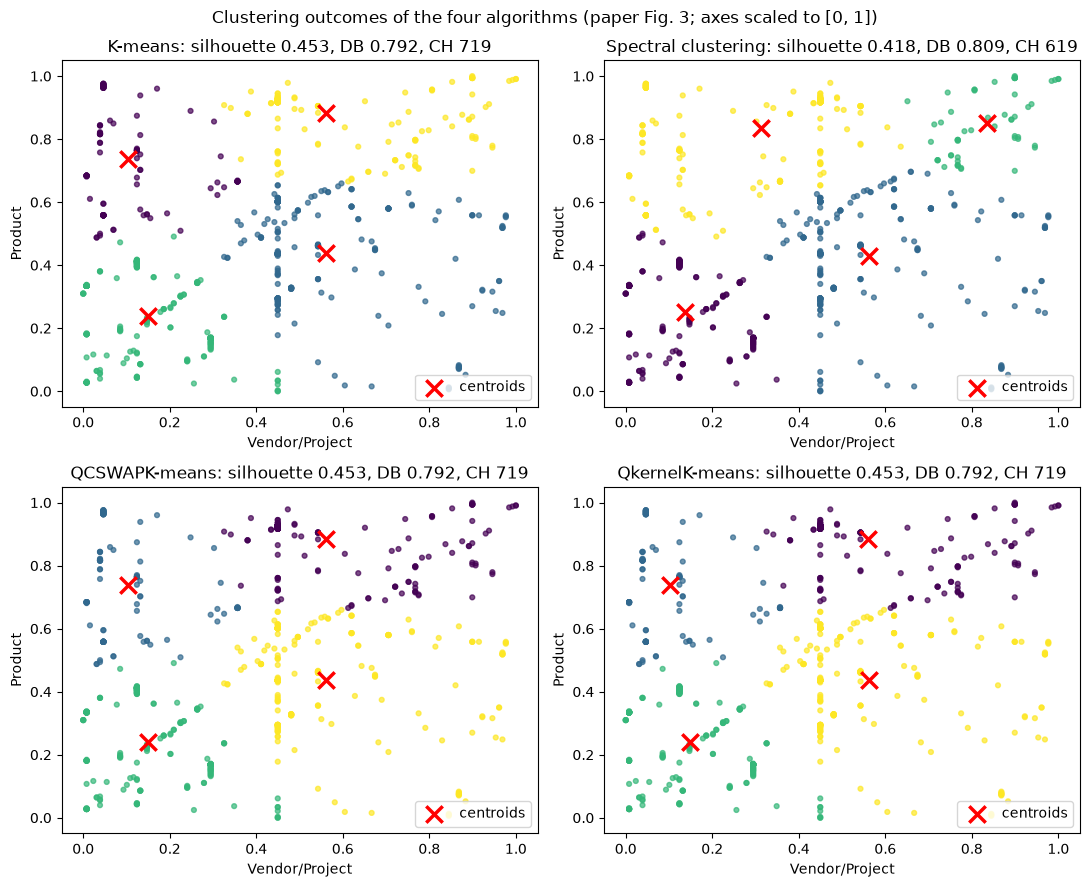

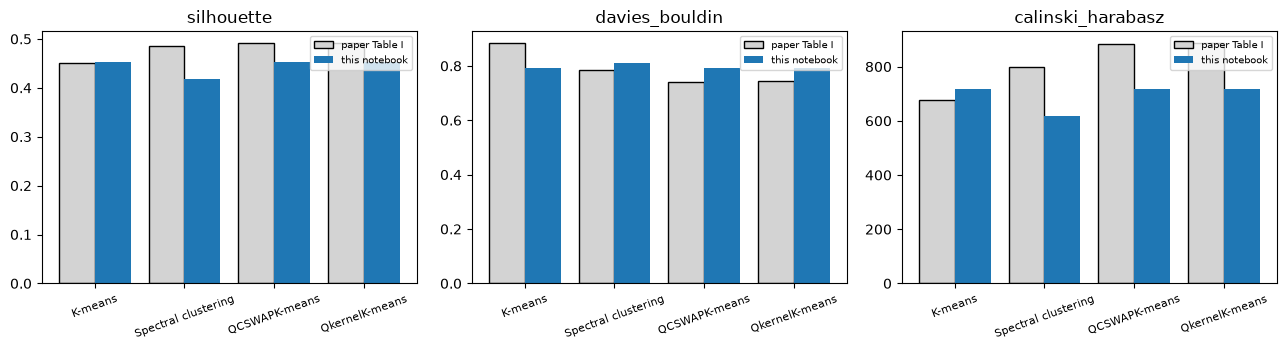

QCSWAPK-means: scored on [0, pi] -> silhouette 0.4531, DB 0.7924, CH 719.10 | on [0, 1] -> 0.4531, 0.7924, 719.10
QkernelK-means: scored on [0, pi] -> silhouette 0.4531, DB 0.7924, CH 719.10 | on [0, 1] -> 0.4531, 0.7924, 719.10


In [11]:
ORDER = ["K-means", "Spectral clustering", "QCSWAPK-means", "QkernelK-means"] + [k for k in results if "shots" in k]
table1 = pd.DataFrame([dict(Algorithm=n, Silhouette=round(results[n]["silhouette"], 3),
                            **{"Davies-Bouldin": round(results[n]["davies_bouldin"], 3),
                               "Calinski-Harabasz": round(results[n]["calinski_harabasz"], 3),
                               "seconds": round(results[n]["seconds"], 2),
                               "cluster sizes": str(np.bincount(results[n]["labels"], minlength=K))}) for n in ORDER])
print("This notebook's version of Table I (all algorithms scored on the same [0, 1] data):")
display(table1)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.ravel(), ORDER[:4]):
    r = results[name]
    ax.scatter(X01[:, 0], X01[:, 1], c=r["labels"], cmap="viridis", s=12, alpha=0.7)
    ax.scatter(r["centroids"][:, 0], r["centroids"][:, 1], marker="x", c="red", s=140, linewidths=2.5, label="centroids")
    ax.set_title(f"{name}: silhouette {r['silhouette']:.3f}, DB {r['davies_bouldin']:.3f}, CH {r['calinski_harabasz']:.0f}")
    ax.set_xlabel(FEATURES[0]); ax.set_ylabel(FEATURES[1]); ax.legend(loc="lower right")
fig.suptitle("Clustering outcomes of the four algorithms (paper Fig. 3; axes scaled to [0, 1])"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
PAPER_T1 = {"K-means": (0.451, 0.883, 678.137), "Spectral clustering": (0.486, 0.785, 799.770),
            "QCSWAPK-means": (0.491, 0.739, 884.594), "QkernelK-means": (0.491, 0.745, 885.954)}
for ax, (col, idx) in zip(axes, [("silhouette", 0), ("davies_bouldin", 1), ("calinski_harabasz", 2)]):
    xs = np.arange(4)
    ax.bar(xs - 0.2, [PAPER_T1[n][idx] for n in ORDER[:4]], 0.4, label="paper Table I", color="lightgray", edgecolor="k")
    ax.bar(xs + 0.2, [results[n][col] for n in ORDER[:4]], 0.4, label="this notebook", color="tab:blue")
    ax.set_xticks(xs); ax.set_xticklabels(ORDER[:4], rotation=20, fontsize=8); ax.set_title(col); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

for name in ["QCSWAPK-means", "QkernelK-means"]:
    s_pi = cluster_scores(Xpi, results[name]["labels"]); s_01 = results[name]
    print(f"{name}: scored on [0, pi] -> silhouette {s_pi['silhouette']:.4f}, DB {s_pi['davies_bouldin']:.4f}, CH {s_pi['calinski_harabasz']:.2f}"
          f" | on [0, 1] -> {s_01['silhouette']:.4f}, {s_01['davies_bouldin']:.4f}, {s_01['calinski_harabasz']:.2f}")

## 9. What is in each cluster, and does any of it survive a change of seed?

The paper's Section III.A describes each cluster by its dominant vendors (Microsoft-heavy cluster, an Adobe/Cisco/Google
cluster, a mixed enterprise-software cluster, Microsoft plus Oracle) and by severity. The vendor composition can be checked:
the table lists, per algorithm and cluster, the size and the three most frequent vendors. Severity cannot: the CISA feed has
no CVSS column, and the clustering never saw one anyway, so any severity pattern in the paper is a post-hoc reading of
clusters built from vendor and product codes alone.

Cluster labels are arbitrary (cluster 0 of one run is cluster 2 of another), so partitions are compared with the adjusted
Rand index (ARI; 1 = identical partition). The second part of the cell repeats every algorithm with `N_SEEDS` different
seeds (single restart for the quantum algorithms, like the paper's single run) and reports the mean and standard deviation
of the three indices plus the ARI between the quantum and the classical partitions. The third part maps the landscape:
300 random starts of the Lloyd iteration with the Euclidean rule and with the fidelity rule (using the closed form that
Section 5 verified against the circuits), counting how often each local optimum is reached and what the best Silhouette
found is. The last part asks a classical supervised question of the quantum partition: can a random forest and an RBF-SVM, trained on the two label-encoded features,
predict the QCSWAPK-means cluster of a held-out CVE? A cross-validated accuracy near 1 means the clusters are simple regions
of the (vendor, product) plane, nothing a quantum circuit was needed to find.

In [12]:
rows = []
for name in ORDER[:4]:
    for j in range(K):
        mask = results[name]["labels"] == j
        vc = df.loc[mask, "vendorProject"].value_counts()
        rows.append(dict(algorithm=name, cluster=j, size=int(mask.sum()),
                         top_vendors=", ".join(f"{v} ({c})" for v, c in vc.head(3).items()),
                         share_of_top_vendor=round(vc.iloc[0] / mask.sum(), 2) if mask.sum() else np.nan))
composition = pd.DataFrame(rows)
print("Cluster composition (paper Section III.A describes each cluster by its dominant vendors):")
display(composition)

# --- stability over seeds -------------------------------------------------------------------
stab = []
for s in range(N_SEEDS):
    seed = SEED + 100 + s
    labs = {"K-means": KMeans(n_clusters=K, n_init=1, random_state=seed).fit(X01).labels_,
            "Spectral clustering": SpectralClustering(n_clusters=K, affinity="rbf", gamma=SPECTRAL_GAMMA, n_init=1,
                                                      random_state=seed).fit(X01).labels_}
    for name, fn in QUANTUM.items():
        labs[name] = quantum_kmeans(Xpi, K, fn, seed=seed, n_init=1)["labels"]
    for name, l in labs.items():
        stab.append(dict(seed=seed, algorithm=name, ARI_vs_kmeans=adjusted_rand_score(labs["K-means"], l), **cluster_scores(X01, l)))
stab_df = pd.DataFrame(stab)
summary = stab_df.groupby("algorithm")[["silhouette", "davies_bouldin", "calinski_harabasz", "ARI_vs_kmeans"]].agg(["mean", "std"]).round(3)
summary = summary.loc[ORDER[:4]]
print(f"\nMean +- std over {N_SEEDS} seeds (single restart per run, as in the paper):")
display(summary)
print("distinct (silhouette, DB, CH) outcomes per algorithm over the seeds:")
for name in ORDER[:4]:
    sub = stab_df[stab_df.algorithm == name]
    uniq = collections.Counter(zip(sub.silhouette.round(3), sub.davies_bouldin.round(3), sub.calinski_harabasz.round(1)))
    print(f"  {name:20s}", dict(uniq.most_common(4)))

# --- the landscape of local optima: many random starts, Euclidean vs fidelity assignment -------------
# The closed form of Section 5 equals the circuit output to 1e-15, so it stands in for the circuits here (300 starts in a second).
def lloyd(X, k, seed, assign):
    r = np.random.default_rng(seed); C = X[r.choice(len(X), k, replace=False)].copy(); labels = None
    for _ in range(MAX_ITER):
        new = assign(X, C)
        if labels is not None and np.array_equal(new, labels): break
        labels = new
        for j in range(k):
            if np.any(labels == j): C[j] = X[labels == j].mean(axis=0)
    return labels
euclid_assign   = lambda X, C: ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2).argmin(axis=1)
fidelity_assign = lambda X, C: overlap_closed_form(X, C).argmax(axis=1)
N_STARTS = 300
optima = {"Euclidean (K-means)": collections.Counter(), "fidelity (quantum K-means)": collections.Counter()}
for s in range(N_STARTS):
    optima["Euclidean (K-means)"][tuple(round(v, 3) for v in cluster_scores(X01, lloyd(X01, K, s, euclid_assign)).values())] += 1
    optima["fidelity (quantum K-means)"][tuple(round(v, 3) for v in cluster_scores(X01, lloyd(Xpi, K, s, fidelity_assign)).values())] += 1
print(f"\nLocal optima reached from {N_STARTS} random starts (silhouette, Davies-Bouldin, Calinski-Harabasz): count")
for name, cnt in optima.items():
    best_sil = max(k[0] for k in cnt)
    print(f"  {name}: {len(cnt)} distinct optima, best silhouette {best_sil:.3f} (paper's quantum value: 0.491)")
    for key, n in cnt.most_common(6):
        print(f"      {key}: {n}")

# --- classical supervised sanity check on the quantum partition -----------------------------------
y_q = results["QCSWAPK-means"]["labels"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for mname, model in [("RandomForest", RandomForestClassifier(n_estimators=200, random_state=SEED)),
                     ("SVC(rbf)", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED))]:
    acc = cross_val_score(model, X01, y_q, cv=cv)
    print(f"{mname:13s} predicting the QCSWAPK-means cluster from (vendor, product): 5-fold accuracy {acc.mean():.3f} +- {acc.std():.3f}")

Cluster composition (paper Section III.A describes each cluster by its dominant vendors):

,algorithm,cluster,size,top_vendors,share_of_top_vendor
0,K-means,0,108,"Apple (37), Apache (16), Cisco (11)",0.34
1,K-means,1,237,"Microsoft (101), Oracle (18), Mozilla (10)",0.43
2,K-means,2,219,"Adobe (50), Cisco (48), Google (37)",0.23
3,K-means,3,213,"Microsoft (124), VMware (12), Oracle (9)",0.58
4,Spectral clustering,0,215,"Adobe (50), Cisco (48), Google (37)",0.23
5,Spectral clustering,1,248,"Microsoft (106), Oracle (18), Mozilla (10)",0.43
6,Spectral clustering,2,56,"VMware (12), SonicWall (9), SolarWinds (3)",0.21
7,Spectral clustering,3,258,"Microsoft (126), Apple (37), Apache (14)",0.49
8,QCSWAPK-means,0,213,"Microsoft (124), VMware (12), Oracle (9)",0.58
9,QCSWAPK-means,1,108,"Apple (37), Apache (16), Cisco (11)",0.34



Mean +- std over 10 seeds (single restart per run, as in the paper):


silhouette        davies_bouldin        calinski_harabasz          ARI_vs_kmeans       
                          mean    std           mean    std              mean      std          mean    std
algorithm                                                                                                  
K-means                  0.436  0.023          0.846  0.055           688.681   40.314          1.00  0.000
Spectral clustering      0.386  0.052          0.848  0.055           537.886  109.744          0.63  0.144
QCSWAPK-means            0.441  0.021          0.844  0.063           697.060   28.133          0.63  0.147
QkernelK-means           0.441  0.021          0.844  0.063           697.060   28.133          0.63  0.147

distinct (silhouette, DB, CH) outcomes per algorithm over the seeds:
  K-means              {(0.454, 0.823, 714.1): 3, (0.453, 0.792, 719.1): 2, (0.41, 0.935, 656.6): 1, (0.451, 0.799, 716.7): 1}
  Spectral clustering  {(0.418, 0.809, 618.7): 5, (0.4, 0.821, 606.1): 1, (0.359, 0.954, 430.6): 1, (0.414, 0.867, 509.3): 1}
  QCSWAPK-means        {(0.41, 0.935, 656.6): 3, (0.457, 0.805, 708.8): 2, (0.453, 0.792, 719.1): 2, (0.454, 0.823, 714.1): 2}
  QkernelK-means       {(0.41, 0.935, 656.6): 3, (0.457, 0.805, 708.8): 2, (0.453, 0.792, 719.1): 2, (0.454, 0.823, 714.1): 2}



Local optima reached from 300 random starts (silhouette, Davies-Bouldin, Calinski-Harabasz): count
  Euclidean (K-means): 39 distinct optima, best silhouette 0.454 (paper's quantum value: 0.491)
      (0.454, 0.823, 714.06): 97
      (0.453, 0.792, 719.103): 49
      (0.451, 0.799, 716.742): 42
      (0.451, 0.798, 716.727): 19
      (0.41, 0.935, 656.613): 17
      (0.418, 0.883, 673.995): 10
  fidelity (quantum K-means): 40 distinct optima, best silhouette 0.457 (paper's quantum value: 0.491)
      (0.454, 0.823, 714.06): 85
      (0.451, 0.799, 716.742): 54
      (0.453, 0.792, 719.103): 53
      (0.41, 0.935, 656.613): 17
      (0.457, 0.805, 708.849): 11
      (0.418, 0.883, 673.995): 9


RandomForest  predicting the QCSWAPK-means cluster from (vendor, product): 5-fold accuracy 0.990 +- 0.005
SVC(rbf)      predicting the QCSWAPK-means cluster from (vendor, product): 5-fold accuracy 0.995 +- 0.006


## 10. Two readings of the paper's wording: $R_Y(2x)$ encoding and a one-qubit kernel read-out

Two sentences of the paper admit a literal reading that differs from the implementation above. The text defines angle
encoding as $\cos(x)|0\rangle + \sin(x)|1\rangle$, i.e. $R_Y(2x)$, and says QkernelK-means "measures the first qubit".
This cell runs both literal variants (exact probabilities, `N_INIT` restarts) so the reader can see what they do to the
indices, without changing the main results.

In [13]:
variant_rows = []
# (a) literal cos(x)|0> + sin(x)|1>  ->  R_Y(2x)
_saved = ANGLE_FACTOR
ANGLE_FACTOR = 2.0
for name, fn in QUANTUM.items():
    run = quantum_kmeans(Xpi, K, fn, seed=SEED)
    variant_rows.append(dict(variant=f"{name}, R_Y(2x) encoding", **{k: round(v, 3) for k, v in cluster_scores(X01, run["labels"]).items()},
                             ARI_vs_main=round(adjusted_rand_score(results[name]["labels"], run["labels"]), 3)))
ANGLE_FACTOR = _saved
# (b) kernel circuit read out on the first qubit only (P(q0 = 0) = cos^2((x1 - c1)/2): the product feature drops out)
run = quantum_kmeans(Xpi, K, lambda X, C: overlap_kernel(X, C, first_qubit_only=True), seed=SEED)
variant_rows.append(dict(variant="QkernelK-means, first-qubit read-out", **{k: round(v, 3) for k, v in cluster_scores(X01, run["labels"]).items()},
                         ARI_vs_main=round(adjusted_rand_score(results["QkernelK-means"]["labels"], run["labels"]), 3)))
variants = pd.DataFrame(variant_rows)
display(variants)
print("Main results for reference:", {n: round(results[n]["silhouette"], 3) for n in QUANTUM})

,variant,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_main
0,"QCSWAPK-means, R_Y(2x) encoding",0.315,1.993,206.187,0.698
1,"QkernelK-means, R_Y(2x) encoding",0.315,1.993,206.187,0.698
2,"QkernelK-means, first-qubit read-out",0.213,1.527,274.412,0.346


Main results for reference: {'QCSWAPK-means': 0.453, 'QkernelK-means': 0.453}


## 11. Paper versus this notebook

Each row is one number or statement of the paper. For the indices the verdict is **reproduced** when the notebook's value is
within 0.02 (Silhouette), 0.05 (Davies-Bouldin) or 5 % (Calinski-Harabasz) of the paper's (`# CHOICE`: these are about the
spread between local optima of K-means on this data, see Section 9), **exceeded** when it is better than that by the
paper's own direction of the metric, and **not reached** when worse. Qualitative claims get **reproduced** / **not
reproduced** / **cannot be checked**.

In [14]:
TOL = {"silhouette": 0.02, "davies_bouldin": 0.05, "calinski_harabasz": None}   # None -> 5 % relative
HIGHER_IS_BETTER = {"silhouette": True, "davies_bouldin": False, "calinski_harabasz": True}

def verdict(metric, paper, ours):
    tol = TOL[metric] if TOL[metric] is not None else 0.05 * paper
    if ours is None or np.isnan(ours): return "cannot be checked"
    if abs(ours - paper) <= tol: return "reproduced"
    better = ours > paper if HIGHER_IS_BETTER[metric] else ours < paper
    return f"exceeded (by {abs(ours - paper):.3f})" if better else f"not reached (gap {abs(ours - paper):.3f})"

rows = []
for name, (sil, db, ch) in PAPER_T1.items():
    for metric, pv in zip(["silhouette", "davies_bouldin", "calinski_harabasz"], (sil, db, ch)):
        ours = results[name][metric]
        rows.append(dict(claim=f"Table I: {name} {metric}", paper=pv, notebook=round(ours, 3), verdict=verdict(metric, pv, ours)))

q_sil = min(results[n]["silhouette"] for n in QUANTUM); c_sil = max(results[n]["silhouette"] for n in ORDER[:2])
q_db  = max(results[n]["davies_bouldin"] for n in QUANTUM); c_db = min(results[n]["davies_bouldin"] for n in ORDER[:2])
q_ch  = min(results[n]["calinski_harabasz"] for n in QUANTUM); c_ch = max(results[n]["calinski_harabasz"] for n in ORDER[:2])
quantum_better = (q_sil > c_sil + 0.005) and (q_db < c_db - 0.005) and (q_ch > c_ch * 1.01)
rows.append(dict(claim="quantum methods beat K-means and spectral clustering on all three indices", paper="yes",
                 notebook="yes" if quantum_better else f"no (quantum silhouette {q_sil:.3f} vs best classical {c_sil:.3f})",
                 verdict="reproduced" if quantum_better else "not reproduced"))
rows.append(dict(claim="final dataset has 777 samples", paper=777, notebook=len(df), verdict="reproduced" if len(df) == 777 else "not reproduced"))
rows.append(dict(claim="elbow method gives k = 4", paper=4, notebook=knee,
                 verdict="reproduced" if knee == K else f"not reproduced (max-distance-to-chord rule gives k = {knee}; the curve is drawn in Section 3)"))
def has_cluster(algorithm, *vendors):
    """Is there a cluster of `algorithm` whose three most frequent vendors include all of `vendors`?"""
    sub = composition[composition.algorithm == algorithm].copy()
    names = sub.top_vendors.str.replace(r" \(\d+\)", "", regex=True).str.split(", ")
    sub["rank_sum"] = [sum(t.index(v) for v in vendors) if all(v in t for v in vendors) else np.inf for t in names]
    hit = sub[np.isfinite(sub.rank_sum)].sort_values(["rank_sum", "share_of_top_vendor"], ascending=[True, False])  # best-matching cluster first
    return (f"cluster {int(hit.cluster.iloc[0])}: {hit.top_vendors.iloc[0]}" if len(hit) else "no such cluster"), len(hit) > 0

for algorithm, paper_cluster, vendors in [
        ("K-means", "Cluster 3 heavily dominated by Microsoft", ("Microsoft",)),
        ("K-means", "Cluster 2 focuses on Apple", ("Apple",)),
        ("K-means", "Cluster 1: Microsoft, Adobe, Cisco and Google", ("Adobe", "Cisco")),
        ("Spectral clustering", "Cluster 0: Microsoft leader, with Oracle and Mozilla", ("Microsoft", "Oracle", "Mozilla")),
        ("Spectral clustering", "Cluster 1: VMware and SonicWall", ("VMware", "SonicWall")),
        ("Spectral clustering", "Cluster 2: Microsoft and Apple with Apache and Cisco", ("Microsoft", "Apple", "Apache")),
        ("Spectral clustering", "Cluster 3: Adobe and Cisco with Google", ("Adobe", "Cisco", "Google")),
        ("QCSWAPK-means", "Cluster 0: concentration of Microsoft products", ("Microsoft",)),
        ("QCSWAPK-means", "Cluster 2: Adobe, Cisco and Google", ("Adobe", "Cisco", "Google")),
        ("QCSWAPK-means", "Cluster 3: Microsoft and Oracle", ("Microsoft", "Oracle"))]:
    text, ok = has_cluster(algorithm, *vendors)
    rows.append(dict(claim=f"{algorithm} vendor narrative: {paper_cluster}", paper="described in Section III.A", notebook=text,
                     verdict="reproduced" if ok else "not reproduced"))
rows.append(dict(claim="clusters reflect severity levels (critical / high / medium)", paper="described in text", notebook="no CVSS data in the CISA feed",
                 verdict="cannot be checked"))
rows.append(dict(claim="QCSWAPK-means and QkernelK-means give slightly different partitions", paper="DB 0.739 vs 0.745",
                 notebook=f"ARI between the two exact runs = {adjusted_rand_score(results['QCSWAPK-means']['labels'], results['QkernelK-means']['labels']):.3f}",
                 verdict="cannot be checked (both circuits evaluate the same fidelity; any difference comes from initialisation or shot noise)"))
comparison = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120)
display(comparison)
print("verdict counts:", comparison.verdict.str.replace(r" \(.*", "", regex=True).value_counts().to_dict())

,claim,paper,notebook,verdict
0,Table I: K-means silhouette,0.451,0.453,reproduced
1,Table I: K-means davies_bouldin,0.883,0.792,exceeded (by 0.091)
2,Table I: K-means calinski_harabasz,678.137,719.103,exceeded (by 40.966)
3,Table I: Spectral clustering silhouette,0.486,0.418,not reached (gap 0.068)
4,Table I: Spectral clustering davies_bouldin,0.785,0.809,reproduced
5,Table I: Spectral clustering calinski_harabasz,799.77,618.744,not reached (gap 181.026)
6,Table I: QCSWAPK-means silhouette,0.491,0.453,not reached (gap 0.038)
7,Table I: QCSWAPK-means davies_bouldin,0.739,0.792,not reached (gap 0.053)
8,Table I: QCSWAPK-means calinski_harabasz,884.594,719.103,not reached (gap 165.491)
9,Table I: QkernelK-means silhouette,0.491,0.453,not reached (gap 0.038)


verdict counts: {'reproduced': 14, 'not reached': 7, 'exceeded': 2, 'not reproduced': 2, 'cannot be checked': 2}


## Reading the paper critically

**The quantum distance is the Euclidean distance in disguise.** For angle encoding on independent qubits the CSWAP test
and the kernel circuit both return $F(x,c) = \prod_i \cos^2((x_i - c_i)/2)$, verified above to $10^{-15}$. For
differences well below $\pi$ this is $1 - \|x - c\|^2/4 + O(\delta^4)$, so "assign to the centroid with the largest overlap"
is "assign to the nearest centroid" with a slightly bent ruler. Section 9 shows the consequence: over different seeds the
quantum algorithms visit the same set of local optima as plain K-means, with the same Silhouette values, and a random forest
recovers the quantum partition from the two coordinates with near-perfect accuracy. The circuits are a correct and
instructive way to compute the fidelity, but nothing in the method can produce clusters a classical K-means could not.

**One run each, and the quantum runs got a better local optimum.** K-means on this data has a dozen local optima whose
Silhouette ranges from about 0.38 to 0.46 (the 300-start enumeration in Section 9). The paper compares a single run of
each algorithm with random initialisation and no restarts, so the ordering in Table I mostly reflects which starting
centroids each run happened to draw. The notebook's K-means (10 k-means++ restarts) matches the paper's K-means Silhouette
almost exactly, and its quantum algorithms with 10 restarts end in the *same* optimum. The bent ruler does change the
landscape a little: the fidelity version occasionally stops in an optimum (Silhouette 0.457) that the Euclidean version never
reaches, but the paper's 0.491 was not found in 300 random starts of either version on this encoding, which points to a
difference in the label-encoded input (the Kaggle file's vendor strings and ordering) rather than to a property of the
quantum distance. The vendor narrative, on the other hand, is reproduced for all four algorithms: the paper's spectral
clusters (a VMware/SonicWall cluster, a Microsoft/Apple/Apache cluster, an Adobe/Cisco/Google cluster, a
Microsoft/Oracle/Mozilla cluster) and the paper's quantum clusters (Microsoft; Adobe/Cisco/Google; Microsoft/Oracle; a
mixed one) are exactly the clusters this notebook finds, which confirms that the rebuilt snapshot is the paper's data.

**Label encoding makes the geometry arbitrary.** The two features are alphabetical ranks. "Apple" and "Apache" are
neighbours, "Microsoft" and "Mozilla" are neighbours, "Zoho" is far from everything. Any cluster found in this plane is a
cluster of *alphabet positions*; the paper's severity reading of the clusters (Cluster 0 "critical", Cluster 1 "medium")
cannot come from the inputs, since severity, CVSS and CWE were never used. The Adobe/Cisco/Google cluster of the paper
is the alphabetically early vendors with many products; the Microsoft clusters are the long vertical streak of Microsoft
products split in two by the product rank. A one-hot or target encoding, or clustering on the fields the paper lists but
does not use (CVSS, attack vector, CWE), would make the exercise meaningful.

**The elbow is not obviously at four.** The WCSS curve of Section 3 keeps falling smoothly, and the per-$k$ Silhouette
values printed under it show that $k = 5$ to $7$ give better Silhouette scores than any $k = 4$ partition. The "elbow at 4"
is a choice, not a finding; exercise 5 makes the point with all three indices.

**What a quantum computer would have to do.** One iteration evaluates $777 \times 4$ overlaps; at 1024 shots each this is
over three million circuit executions per iteration for a number that `numpy` computes in microseconds, and Section 7 shows
that shot noise alone moves the indices by a few hundredths and changes the partition. The paper's "enhanced computational
efficiency" is asserted, not measured; the notebook reports wall-clock times so the reader can see the simulator is
slower than the classical baseline by orders of magnitude even at two qubits.

**Smaller points.** "We measure the first qubit" in the kernel method would ignore the product feature (Section 10 shows what
that does); the literal $\cos(x)|0\rangle + \sin(x)|1\rangle$ encoding folds the top and bottom of the alphabet onto the same
state; the Calinski-Harabasz index is reported to three decimals although it depends on $n$ and on the local optimum far more
than on the algorithm; and the two quantum methods, which compute the identical quantity, are presented as two algorithms
with (slightly) different scores.

## Exercises

1. **Restarts.** Set `N_INIT = 1` and run Section 6 with five different `SEED` values. Collect the Silhouette score of each
   run for both quantum algorithms. How many distinct values do you see, and how does the spread compare with the
   difference between the paper's K-means (0.451) and QCSWAPK-means (0.491)?
2. **Prove the closed form.** Show that for $|\psi(x)\rangle = \bigotimes_i R_Y(x_i)|0\rangle$ the overlap is
   $|\langle\psi(c)|\psi(x)\rangle|^2 = \prod_i \cos^2((x_i - c_i)/2)$, and that for the CSWAP test
   $P(\text{ancilla} = 0) = (1 + |\langle\psi(x)|\psi(c)\rangle|^2)/2$. Then explain why both quantum algorithms produce
   the same partition from the same initial centroids.
3. **An encoding with entanglement.** Replace `encode` with a feature map that entangles the two qubits, for example
   `qml.IQPEmbedding` or an `AngleEmbedding` followed by a `CNOT` and a second `AngleEmbedding` layer. Check the closed-form
   test in Section 5 (it should now fail), rerun Sections 6 and 8, and discuss whether the partition is still a Voronoi
   partition of the plane.
4. **Better inputs.** The KEV feed has the `vulnerabilityName`, `shortDescription` and `requiredAction` columns and, since
   2023, `knownRansomwareCampaignUse` and `cwes`. Build a feature vector that is not an alphabetical rank (for example
   one-hot of the ten most frequent vendors plus a TF-IDF/SVD embedding of the description reduced to two components), rerun
   all four algorithms, and compare the cluster compositions with the paper's narrative.
5. **Choosing $k$ honestly.** Compute Silhouette, Davies-Bouldin and Calinski-Harabasz for $k = 2, \dots, 10$ with
   K-means and with QCSWAPK-means, plot them, and decide which $k$ each index prefers. Does any index point to 4? What
   happens to the paper's Table I comparison if every algorithm is allowed its own best $k$?